# HW 7, Problem 2: Kalman filter for the damped oscillator

## Model, data, and filter

The oscillator $\ddot z + 2\xi\omega\dot z + \omega^2 z = 0$ becomes a first-order system in $x = (z, \dot z)^T$:
$$\dot x = A x, \qquad A = \begin{pmatrix} 0 & 1 \\ -\omega^2 & -2\xi\omega \end{pmatrix}.$$
Explicit Euler with step $\Delta t$ gives the linear model used for both the truth and the filter ($Q_k = 0$):
$$x_{k+1} = M x_k, \qquad M = I_2 + \Delta t A = \begin{pmatrix} 1 & \Delta t \\ -\Delta t\,\omega^2 & 1 - 2\Delta t\,\xi\omega \end{pmatrix}.$$

Observations of position only, at every step $t_k = k\Delta t$, $k = 1, \dots, N$ (none at $t_0$):
$$y_k = H x_k^\dagger + v_k, \qquad H = \begin{pmatrix} 1 & 0 \end{pmatrix}, \quad v_k \sim N(0, R), \quad R = 5.$$

Kalman filter, starting from the prior $X_0 \sim N(m_0^a, P_0^a)$:

* **Forecast:** $m_k^f = M m_{k-1}^a$, $\quad P_k^f = M P_{k-1}^a M^T$.
* **Analysis:** $S_k = H P_k^f H^T + R$, $\quad K_k = P_k^f H^T S_k^{-1}$ (computed by solving $S_k K_k^T = H P_k^f$),
  $$m_k^a = m_k^f + K_k\,(y_k - H m_k^f), \qquad P_k^a = (I - K_k H)\,P_k^f\,(I - K_k H)^T + K_k R K_k^T.$$
  The last line is the Joseph form; it equals $(I - K_k H) P_k^f$ for this $K_k$ but stays symmetric positive semidefinite in floating point over $10^5$ cycles.

The model lives in `src/da_models/damped_oscillator.py` and the filter (forecast, analysis, cycling driver, RMSE/spread) in `src/da_models/kalman.py`, so Problem 3 and later assignments can reuse them.

**Numerical settings:** $\omega = 1$, $\xi = 10^{-3}$, $\Delta t = 10^{-3}$, $T = 100$ ($N = 100{,}000$ steps), $x_0^\dagger = (1, 2)^T$, $m_0^a = 0$, $P_0^a = I_2$, $R = 5$. The only random draw is the observation noise, from `np.random.default_rng(513)`.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from da_models import damped_oscillator as osc
from da_models.kalman import (
    simulate_linear, synthetic_observations, run_kf, perfect_model_posterior, rmse_and_spread,
)

# ---- settings: change these and re-run ----
OMEGA = 1.0                      # natural frequency
XI = 1e-3                        # damping ratio
DT = 1e-3                        # time step
T_FINAL = 100.0                  # length of the run (dimensionless time)
X0_TRUE = np.array([1.0, 2.0])   # true (z, z') at t = 0
R_VAR = 5.0                      # observation-error variance
M0 = np.zeros(2)                 # prior mean m_0^a
P0 = np.eye(2)                   # prior covariance P_0^a
SEED_OBS = 513                   # observation-noise stream (the only random draw)

N = int(round(T_FINAL / DT))
t = DT * np.arange(N + 1)        # t_0, ..., t_N
t_obs = t[1:]                    # observation times t_1, ..., t_N
M = osc.euler_matrix(OMEGA, XI, DT)
H = np.array([[1.0, 0.0]])
R = np.array([[R_VAR]])

print("M =\n", M)
print(f"N = {N} steps,  spectral radius of M = {osc.euler_spectral_radius(OMEGA, XI, DT):.10f}")
dt_max = osc.euler_max_stable_dt(OMEGA, XI)
print(f"explicit Euler decays only for dt < 2*xi/omega = {dt_max:.3g}")
if DT >= dt_max:
    warnings.warn("dt is too large for these omega, xi: the Euler solution will grow instead of decay.")

# plot styling shared by every figure
C = dict(truth="#0b0b0b", kf="#2a78d6", obs="#8c8a85", first="#2a78d6", second="#eb6834")
plt.rcParams.update({
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 110,
})

M =
 [[ 1.        0.001   ]
 [-0.001     0.999998]]
N = 100000 steps,  spectral radius of M = 0.9999995000
explicit Euler decays only for dt < 2*xi/omega = 0.002


## (a) True state

Simulate $x_{k+1}^\dagger = M x_k^\dagger$ from $x_0^\dagger = (1, 2)^T$ for $N$ steps.

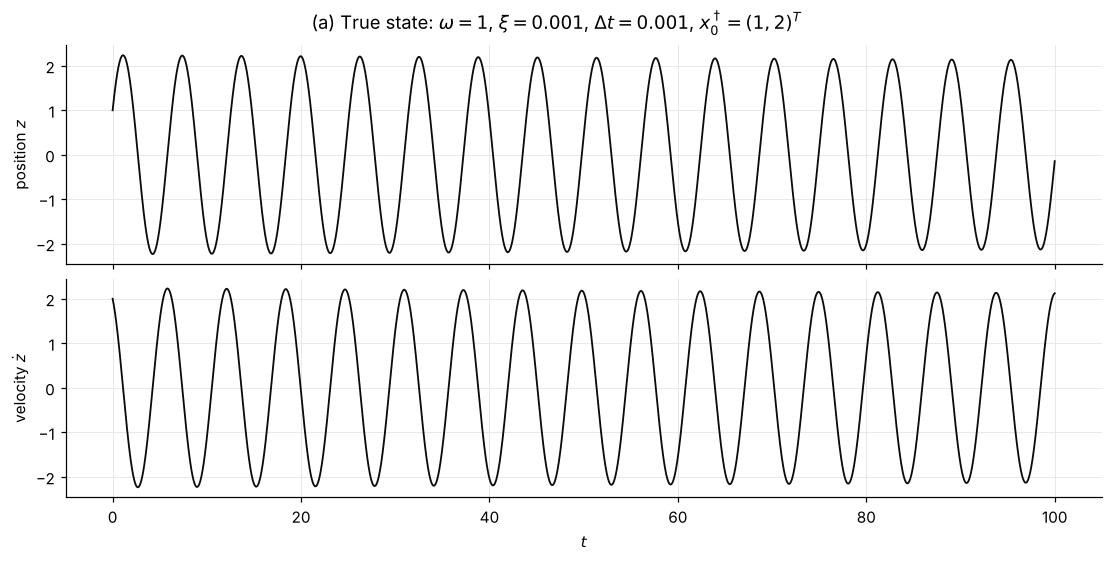

In [2]:
truth = simulate_linear(M, X0_TRUE, N)      # shape (N+1, 2): columns z, z'

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, constrained_layout=True)
axes[0].plot(t, truth[:, 0], color=C["truth"])
axes[0].set_ylabel("position $z$")
axes[1].plot(t, truth[:, 1], color=C["truth"])
axes[1].set_ylabel(r"velocity $\dot z$")
axes[1].set_xlabel("$t$")
fig.suptitle(rf"(a) True state: $\omega = {OMEGA:g}$, $\xi = {XI:g}$, $\Delta t = {DT:g}$, "
             rf"$x_0^\dagger = ({X0_TRUE[0]:g}, {X0_TRUE[1]:g})^T$")
plt.show()

## (b) Synthetic observations

$y_k = z_k^\dagger + v_k$, $v_k \sim N(0, 5)$, at every step $k = 1, \dots, N$ (100,000 observations). The dots are drawn small, semi-transparent, and rasterized so the exported PDF stays light.

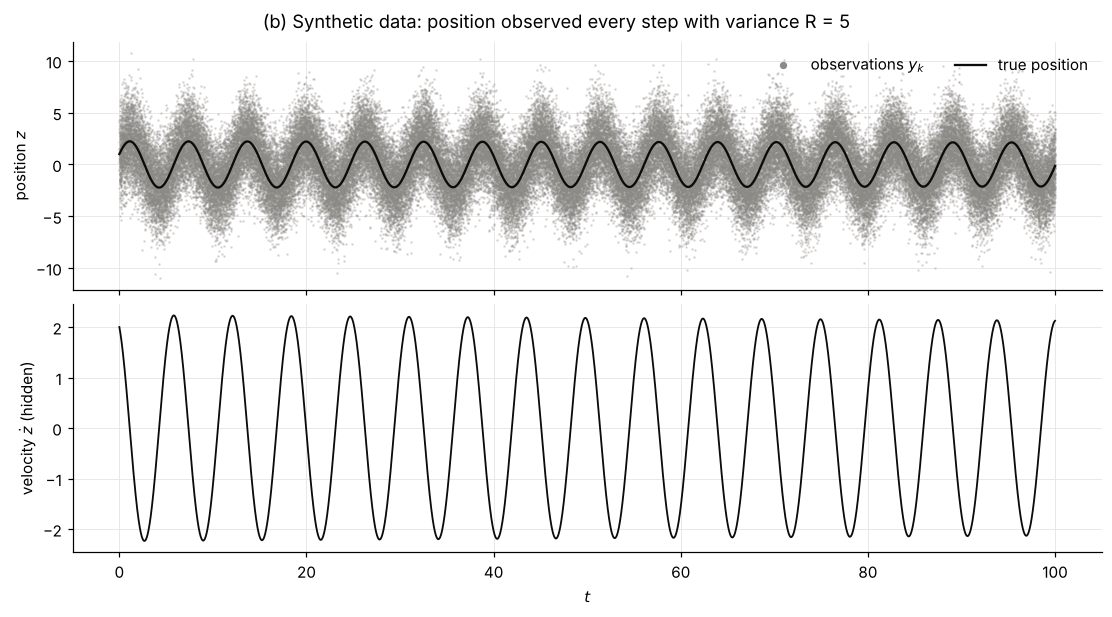

observation errors: mean -0.0058, std 2.2410  (sqrt(R) = 2.2361)


In [3]:
rng_obs = np.random.default_rng(SEED_OBS)
Y = synthetic_observations(truth, H, R, rng_obs)   # shape (N, 1), Y[k-1] = y_k

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, constrained_layout=True)
axes[0].plot(t_obs, Y[:, 0], ".", ms=1.5, color=C["obs"], alpha=0.25, rasterized=True,
             label="observations $y_k$")
axes[0].plot(t, truth[:, 0], color=C["truth"], lw=1.5, label="true position")
axes[0].set_ylabel("position $z$")
leg = axes[0].legend(loc="upper right", ncol=2, markerscale=5)
leg.legend_handles[0].set_alpha(1)
axes[1].plot(t, truth[:, 1], color=C["truth"], label="true velocity")
axes[1].set_ylabel(r"velocity $\dot z$ (hidden)")
axes[1].set_xlabel("$t$")
fig.suptitle(f"(b) Synthetic data: position observed every step with variance R = {R_VAR:g}")
plt.show()

v = Y[:, 0] - truth[1:, 0]
print(f"observation errors: mean {v.mean():+.4f}, std {v.std():.4f}  (sqrt(R) = {np.sqrt(R_VAR):.4f})")

## Check: the filter against a batch posterior

With $Q = 0$ every observation is a linear measurement of $x_0$: $y_j = (HM^j)x_0 + v_j$. So the posterior of $x_k$ given $y_1, \dots, y_k$ can be computed in one batch, without running the filter (`perfect_model_posterior` in `kalman.py`). The filter's $m_k^a$ and $P_k^a$ should match it to rounding error.

In [4]:
K_CHECK = 5000
kf_short = run_kf(M, H, R, Y[:K_CHECK], M0, P0)

print(f"{'k':>6} {'max |m_KF - m_batch|':>22} {'max |P_KF - P_batch| / max|P|':>32}")
for k in [1, 10, 100, 1000, K_CHECK]:
    m_b, P_b = perfect_model_posterior(M, H, R, Y, M0, P0, k)
    dm = np.abs(kf_short["m_a"][k] - m_b).max()
    dP = np.abs(kf_short["P_a"][k] - P_b).max() / np.abs(P_b).max()
    print(f"{k:>6} {dm:>22.2e} {dP:>32.2e}")

     k   max |m_KF - m_batch|    max |P_KF - P_batch| / max|P|
     1               2.78e-17                         1.11e-16
    10               2.22e-16                         1.11e-16
   100               4.44e-16                         2.26e-16
  1000               1.14e-14                         9.62e-15


  5000               1.15e-14                         5.17e-15


## (c) Kalman filter reconstruction

Prior $m_0^a = 0$, $P_0^a = I_2$. Left column: the whole run; right column: zoom on the start. Bottom row: the two components of the gain $K_k = \big(K_k^{(z)}, K_k^{(\dot z)}\big)^T$, the weights applied to the position innovation $y_k - Hm_k^f$ when updating position and velocity.

filter runtime: 3.21 s for 100000 cycles


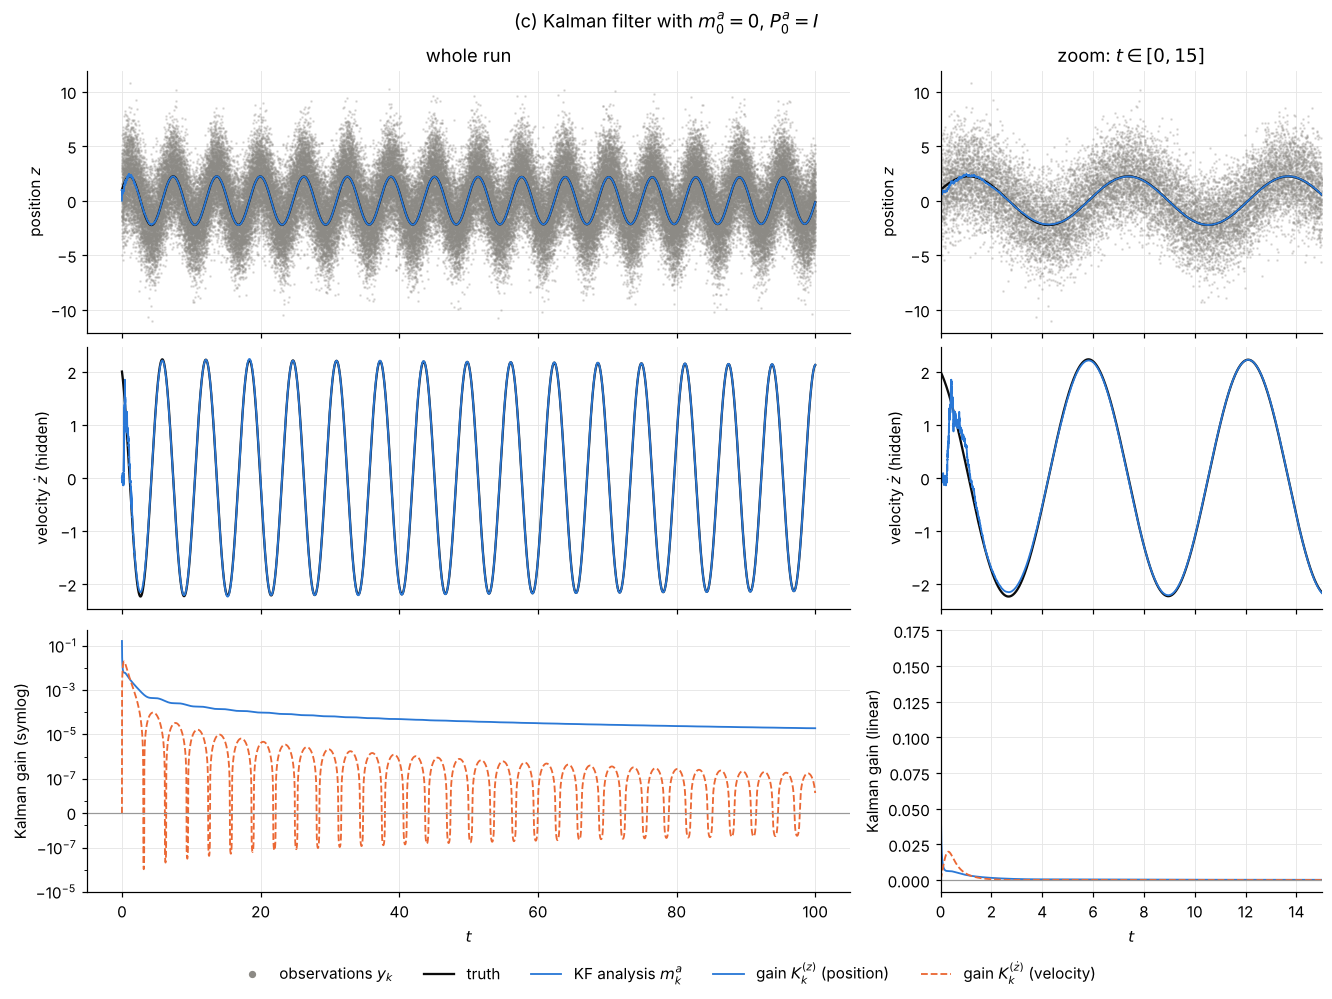

gain at selected times:
  t =  0.001:  K^(z) =  1.667e-01,  K^(z') = -3.333e-10
  t =      1:  K^(z) =  3.554e-03,  K^(z') =  4.530e-03
  t =     10:  K^(z) =  1.903e-04,  K^(z') =  5.630e-06
  t =     50:  K^(z) =  3.920e-05,  K^(z') = -3.556e-09
  t =    100:  K^(z) =  1.910e-05,  K^(z') =  2.266e-08


In [5]:
tic = time.perf_counter()
kf = run_kf(M, H, R, Y, M0, P0)
print(f"filter runtime: {time.perf_counter() - tic:.2f} s for {N} cycles")

ZOOM = 15.0
K = kf["K"][:, :, 0]     # shape (N, 2): K^(z), K^(z')

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex="col", constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[2, 1]))
for col in range(2):
    ax = axes[0, col]
    ax.plot(t_obs, Y[:, 0], ".", ms=1.5, color=C["obs"], alpha=0.25, rasterized=True,
            label="observations $y_k$")
    ax.plot(t, truth[:, 0], color=C["truth"], lw=1.5, label="truth")
    ax.plot(t, kf["m_a"][:, 0], color=C["kf"], lw=1.2, label="KF analysis $m_k^a$")
    ax.set_ylabel("position $z$")

    ax = axes[1, col]
    ax.plot(t, truth[:, 1], color=C["truth"], lw=1.5)
    ax.plot(t, kf["m_a"][:, 1], color=C["kf"], lw=1.2)
    ax.set_ylabel(r"velocity $\dot z$ (hidden)")

    ax = axes[2, col]
    ax.plot(t_obs, K[:, 0], color=C["first"], label=r"gain $K_k^{(z)}$ (position)")
    ax.plot(t_obs, K[:, 1], color=C["second"], ls="--", label=r"gain $K_k^{(\dot z)}$ (velocity)")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xlabel("$t$")
# K^(z') changes sign, so the whole-run panel uses a symmetric log scale
# (linear within +/- 1e-8, logarithmic outside); the zoom stays linear.
axes[2, 0].set_yscale("symlog", linthresh=1e-8, linscale=0.5)
axes[2, 0].set_yticks([1e-1, 1e-3, 1e-5, 1e-7, 0, -1e-7, -1e-5])
axes[2, 0].set_ylim(-1e-5, 0.5)
axes[2, 0].set_ylabel("Kalman gain (symlog)")
axes[2, 1].set_ylabel("Kalman gain (linear)")
axes[0, 1].set_xlim(0, ZOOM)
axes[0, 1].set_ylim(axes[0, 0].get_ylim())
axes[0, 0].set_title("whole run")
axes[0, 1].set_title(f"zoom: $t \\in [0, {ZOOM:g}]$")

handles, labels = axes[0, 0].get_legend_handles_labels()
h2, l2 = axes[2, 0].get_legend_handles_labels()
leg = fig.legend(handles + h2, labels + l2, loc="outside lower center", ncol=5, markerscale=5)
leg.legend_handles[0].set_alpha(1)
fig.suptitle(r"(c) Kalman filter with $m_0^a = 0$, $P_0^a = I$")
plt.show()

print("gain at selected times:")
for tk in [DT, 1, 10, 50, T_FINAL]:
    k = int(round(tk / DT))
    print(f"  t = {tk:>6g}:  K^(z) = {K[k - 1, 0]: .3e},  K^(z') = {K[k - 1, 1]: .3e}")

### (c) continued: other initial assumptions

Same truth and same observations; only the prior $(m_0^a, P_0^a)$ changes. Edit `INIT_CASES` to try others. Top row: estimation error $m_k^a - x_k^\dagger$ in each component. Bottom row: RMSE and spread (defined in part (d)). All panels use a log time axis ($k \ge 1$) so the start of the run is visible; the spread lines are drawn with decreasing widths so any that coincide remain visible.

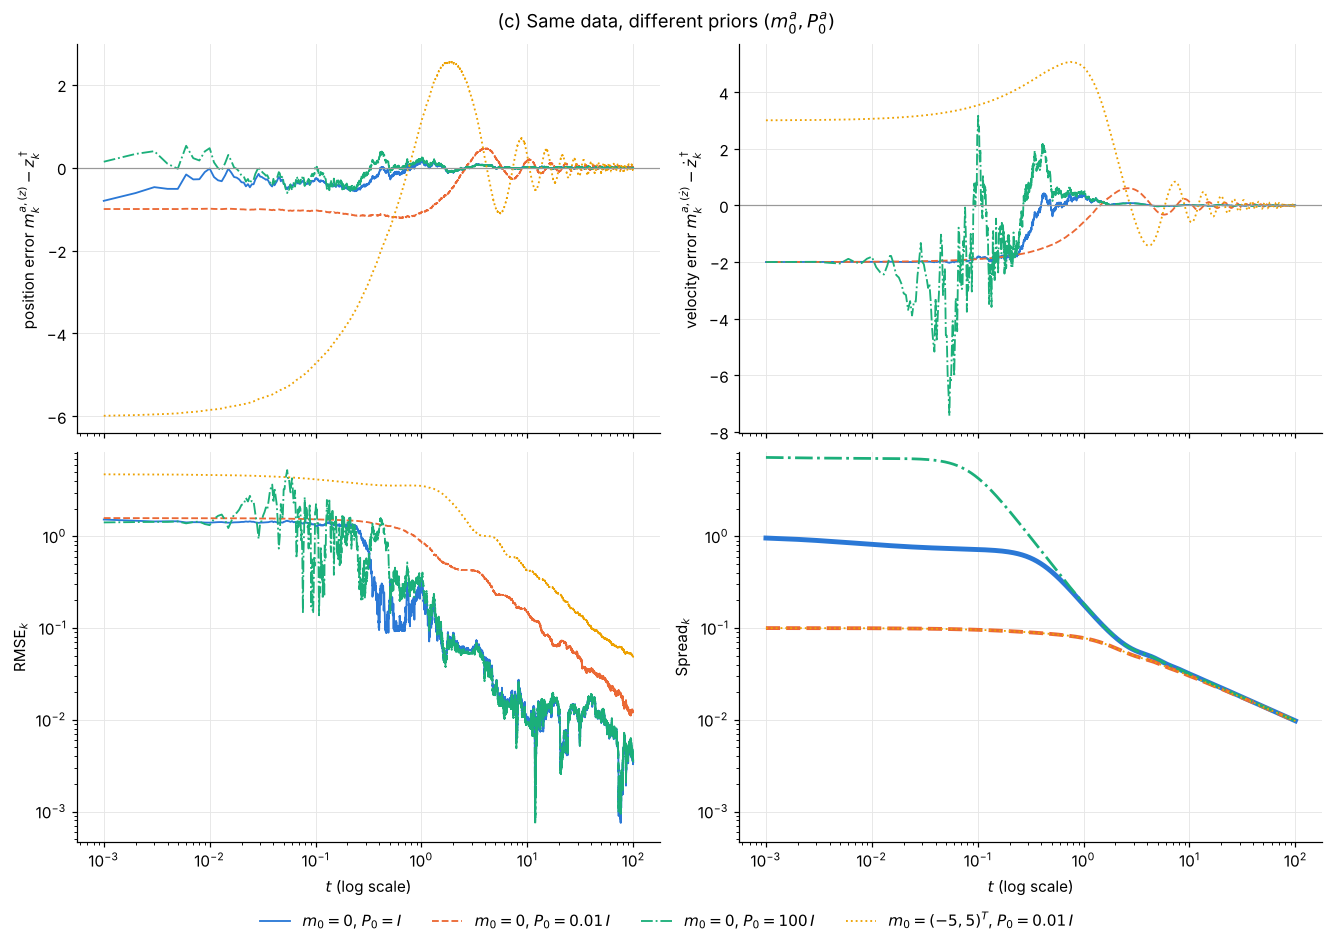

prior                                                  t = 1              t = 10              t = 50             t = 100
                                               RMSE / spread       RMSE / spread       RMSE / spread       RMSE / spread
m_0 = 0, P_0 = I                                0.271 / 0.18     0.0103 / 0.0316     0.00968 / 0.014   0.00343 / 0.00975
m_0 = 0, P_0 = 0.01 I                         0.869 / 0.0779       0.15 / 0.0301     0.0294 / 0.0138     0.0125 / 0.0097
m_0 = 0, P_0 = 100 I                           0.343 / 0.185    0.00925 / 0.0316     0.00977 / 0.014   0.00357 / 0.00975
m_0 = (-5, 5)^T, P_0 = 0.01 I                  3.54 / 0.0779      0.425 / 0.0301     0.0843 / 0.0138     0.0488 / 0.0097


In [6]:
INIT_CASES = {   # label: (m_0^a, P_0^a)
    r"$m_0 = 0$, $P_0 = I$": (np.zeros(2), np.eye(2)),
    r"$m_0 = 0$, $P_0 = 0.01\,I$": (np.zeros(2), 0.01 * np.eye(2)),
    r"$m_0 = 0$, $P_0 = 100\,I$": (np.zeros(2), 100.0 * np.eye(2)),
    r"$m_0 = (-5, 5)^T$, $P_0 = 0.01\,I$": (np.array([-5.0, 5.0]), 0.01 * np.eye(2)),
}
CASE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed order
CASE_STYLES = ["-", "--", "-.", ":"]

init_runs = {}
for label, (m0, p0) in INIT_CASES.items():
    run = run_kf(M, H, R, Y, m0, p0)
    rmse_c, spread_c = rmse_and_spread(run["m_a"], run["P_a"], truth)
    init_runs[label] = dict(run=run, rmse=rmse_c, spread=spread_c)

CASE_WIDTHS = [3.2, 2.5, 1.8, 1.2]    # decreasing, so curves that coincide stay visible

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharex=True, constrained_layout=True)
for (label, res), color, ls, lw in zip(init_runs.items(), CASE_COLORS, CASE_STYLES, CASE_WIDTHS):
    err = res["run"]["m_a"] - truth
    axes[0, 0].semilogx(t[1:], err[1:, 0], color=color, ls=ls, lw=1.2, label=label)
    axes[0, 1].semilogx(t[1:], err[1:, 1], color=color, ls=ls, lw=1.2, label=label)
    axes[1, 0].loglog(t[1:], res["rmse"][1:], color=color, ls=ls, lw=1.2, label=label)
    axes[1, 1].loglog(t[1:], res["spread"][1:], color=color, ls=ls, lw=lw, label=label)
for ax in axes[0]:
    ax.axhline(0, color="0.6", lw=0.8)
axes[0, 0].set_ylabel(r"position error $m_k^{a,(z)} - z_k^\dagger$")
axes[0, 1].set_ylabel(r"velocity error $m_k^{a,(\dot z)} - \dot z_k^\dagger$")
axes[1, 0].set_ylabel(r"RMSE$_k$")
axes[1, 1].set_ylabel(r"Spread$_k$")
axes[1, 1].sharey(axes[1, 0])
for ax in axes[1]:
    ax.set_xlabel("$t$ (log scale)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
fig.suptitle("(c) Same data, different priors $(m_0^a, P_0^a)$")
plt.show()

print(f"{'prior':<40}" + "".join(f"{'t = ' + format(tk, 'g'):>20}" for tk in [1, 10, 50, 100]))
print(f"{'':<40}" + "".join(f"{'RMSE / spread':>20}" for _ in range(4)))
for label, res in init_runs.items():
    vals = []
    for tk in [1, 10, 50, 100]:
        k = int(round(tk / DT))
        vals.append(f"{res['rmse'][k]:.3g} / {res['spread'][k]:.3g}")
    plain = label.replace("$", "").replace("\\,", " ")
    print(f"{plain:<40}" + "".join(f"{v:>20}" for v in vals))

**Answer to 2(c).** *What happens when you make other, more “wrong” assumptions about the initial state?*



## (d) RMSE and spread

For the run in (c) with $m_0^a = 0$, $P_0^a = I_2$:
$$\mathrm{RMSE}_k = \sqrt{\tfrac12 \lVert m_k^a - x_k^\dagger \rVert_2^2}, \qquad \mathrm{Spread}_k = \sqrt{\tfrac12 \operatorname{tr}(P_k^a)}.$$
Left: linear axes. Right: the same curves on log–log axes ($k \ge 1$).

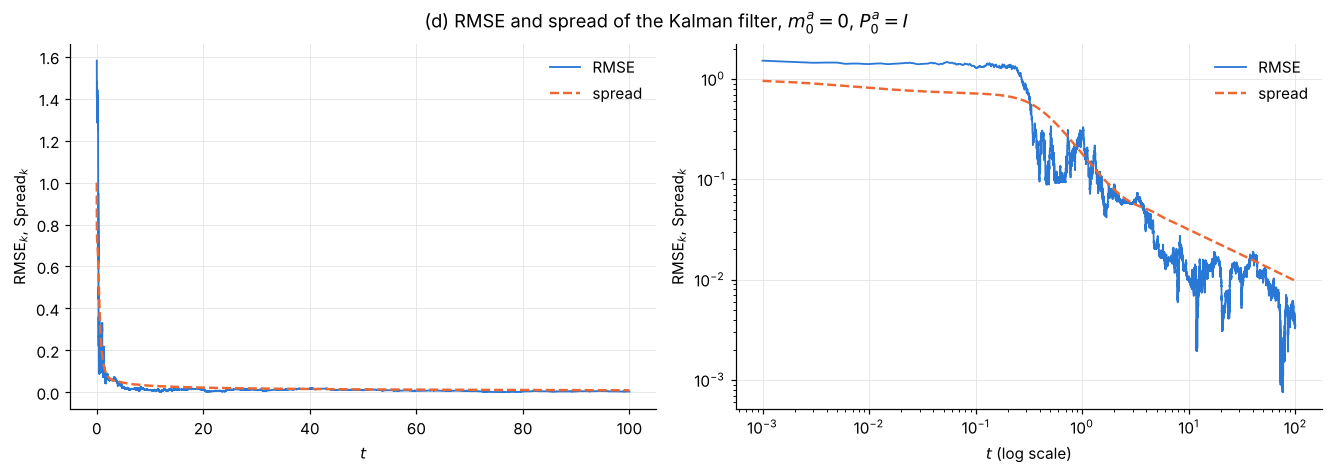

       t       RMSE     spread
       0      1.581          1
   0.001      1.523     0.9574
     0.1      1.298      0.718
       1      0.271     0.1798
      10    0.01028    0.03157
      50   0.009681    0.01396
     100   0.003426   0.009751

root-mean-square over t in [50, 100]:  RMSE 0.006475,  spread 0.01156


In [7]:
rmse, spread = rmse_and_spread(kf["m_a"], kf["P_a"], truth)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].plot(t, rmse, color=C["first"], label="RMSE")
axes[0].plot(t, spread, color=C["second"], ls="--", lw=1.6, label="spread")
axes[0].set_xlabel("$t$")
axes[1].loglog(t[1:], rmse[1:], color=C["first"], label="RMSE")
axes[1].loglog(t[1:], spread[1:], color=C["second"], ls="--", lw=1.6, label="spread")
axes[1].set_xlabel("$t$ (log scale)")
for ax in axes:
    ax.set_ylabel("RMSE$_k$, Spread$_k$")
    ax.legend(loc="upper right")
fig.suptitle(r"(d) RMSE and spread of the Kalman filter, $m_0^a = 0$, $P_0^a = I$")
plt.show()

print(f"{'t':>8} {'RMSE':>10} {'spread':>10}")
for tk in [0, DT, 0.1, 1, 10, 50, T_FINAL]:
    k = int(round(tk / DT))
    print(f"{tk:>8g} {rmse[k]:>10.4g} {spread[k]:>10.4g}")
half = slice(N // 2, None)
print(f"\nroot-mean-square over t in [{T_FINAL / 2:g}, {T_FINAL:g}]:  "
      f"RMSE {np.sqrt(np.mean(rmse[half] ** 2)):.4g},  spread {np.sqrt(np.mean(spread[half] ** 2)):.4g}")

**Answer to 2(d).** *What can you conclude from this plot?*



## AI use (draft — edit as needed)

Claude (Anthropic) helped write and debug the code for Problem 2: the `damped_oscillator.py` and `kalman.py` modules and the code cells in this notebook. The answers to 2(c) and 2(d) are my own.